[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://google.com)

# SMAP exploration

* **Author:** Gradient Descent Farmers

### Description of the dataset

SMAP provides both direct observational data and advanced Level-4 assimilated models, yielding several primary variables you can use as base inputs for your feature engineering process.

Available SMAP Variables

* Surface Soil Moisture: The primary observation, measuring the moisture lodged in the top two inches of Earth's soils with high accuracy and resolution.   
* Surface Temperature: Measurements of Earth's surface temperatures captured via SMAP's radiometer.   
* Root-Zone Soil Moisture (Level-4 Product): While the satellite only "sees" the top two inches, NASA assimilates this data into land surface models to provide 3-hourly, 9-km resolution estimates of moisture down to 1 meter in the root zone.
* Freeze/Thaw State: Data capturing the physical state of the landscape, which is used to track seasonal thaw progression and front extensions across different latitudes.
* Carbon Fluxes: Variables detailing the circulation of carbon, tracking its transfer from the air to soil, rocks, surface water, and frozen surfaces. Level-4 products specifically provide daily estimates of net ecosystem CO2 exchange.
* Sea Surface Salinity: Measurements of freshwater movement in oceans, though this will likely be dropped during your feature selection process for agricultural tasks.

## Libraries

In [13]:
!pip install earthaccess

## Earthaccess Data (SMAP)

We are required to create an account at [Earth Data Login](https://urs.earthdata.nasa.gov/profile) to access the files and be able to login().

In [14]:
import earthaccess

earthaccess.login()

Since I am using google colab, this data is stored within google colab virtual filesystem. For the purpose of this exploration I decided to retrieve data from this dataset: https://nsidc.org/data/spl4smgp/versions/8

* **SPL4SMGP** is the SMAP Level-4 Global 3-hourly 9-km product, which provides assimilated estimates of both surface soil moisture (top 5 cm) and root-zone soil moisture (down to 1 meter), alongside carbon fluxes and surface temperature. Because it uses land surface models to extrapolate the satellite's surface readings deeper into the soil, it is highly valuable for agricultural modeling.

In [15]:
# Search for SMAP data (e.g., Level 4 Surface and Root Zone Soil Moisture)
# The short_name "SPL4SMGP" refers to the L4 Global 3-hourly 9 km product
results = earthaccess.search_data(
    short_name="SPL4SMGP", 
    bounding_box=(-114, 30, -109, 40), # (min_lon, min_lat, max_lon, max_lat)
    temporal=("2025-01-01", "2025-12-31"),
    count=10 # Remove or increase count to get full date range
)

files = earthaccess.download(results, "./smap/smap_data")

QUEUEING TASKS | :   0%|          | 0/10 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/10 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/10 [00:00<?, ?it/s]

In [16]:
results

[Collection: {'Version': '008', 'ShortName': 'SPL4SMGP'}
 Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180, 'SouthBoundingCoordinate': -85.04456, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 85.04456}]}}}
 Temporal coverage: {'RangeDateTime': {'EndingDateTime': '2025-01-01T00:00:00.000Z', 'BeginningDateTime': '2024-12-31T21:00:00.000Z'}}
 Size(MB): 138.6322021484375
 Data: ['https://data.nsidc.earthdatacloud.nasa.gov/nsidc-cumulus-prod-protected/SMAP/SPL4SMGP/008/2024/12/31/SMAP_L4_SM_gph_20241231T223000_Vv8011_001.h5'],
 Collection: {'Version': '008', 'ShortName': 'SPL4SMGP'}
 Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180, 'SouthBoundingCoordinate': -85.04456, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 85.04456}]}}}
 Temporal coverage: {'RangeDateTime': {'EndingDateTime': '2025-01-01T03:00:00.000Z', 'BeginningDateTime': '202

In [17]:
files

[PosixPath('smap/smap_data/SMAP_L4_SM_gph_20241231T223000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250101T013000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250101T043000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250101T073000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250101T103000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250101T133000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250101T163000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250101T193000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250101T223000_Vv8011_001.h5'),
 PosixPath('smap/smap_data/SMAP_L4_SM_gph_20250102T013000_Vv8011_001.h5')]

In [20]:
import h5py

file_path = str(files[0])

with h5py.File(file_path, "r") as h5_file:
    print("Top-level groups/keys:", list(h5_file.keys()))
    
    # Recursive function to inspect all datasets inside the HDF5 file
    def print_dataset_info(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"Dataset: {name:50} | Shape: {obj.shape} | Dtype: {obj.dtype}")

    # Inspect the Geophysical Data group (where soil moisture lives)
    if "Geophysical_Data" in h5_file:
        print("\n--- Variables in Geophysical_Data ---")
        h5_file["Geophysical_Data"].visititems(print_dataset_info)
    else:
        h5_file.visititems(print_dataset_info)

Top-level groups/keys: ['EASE2_global_projection', 'Geophysical_Data', 'Metadata', 'cell_column', 'cell_lat', 'cell_lon', 'cell_row', 'time', 'x', 'y']

--- Variables in Geophysical_Data ---
Dataset: baseflow_flux                                      | Shape: (1624, 3856) | Dtype: float32
Dataset: depth_to_water_table_from_surface                  | Shape: (1624, 3856) | Dtype: float32
Dataset: free_surface_water_on_peat_flux                    | Shape: (1624, 3856) | Dtype: float32
Dataset: heat_flux_ground                                   | Shape: (1624, 3856) | Dtype: float32
Dataset: heat_flux_latent                                   | Shape: (1624, 3856) | Dtype: float32
Dataset: heat_flux_sensible                                 | Shape: (1624, 3856) | Dtype: float32
Dataset: height_lowatmmodlay                                | Shape: (1624, 3856) | Dtype: float32
Dataset: land_evapotranspiration_flux                       | Shape: (1624, 3856) | Dtype: float32
Dataset: land_fra

In [24]:
h5_file

<Closed HDF5 file>

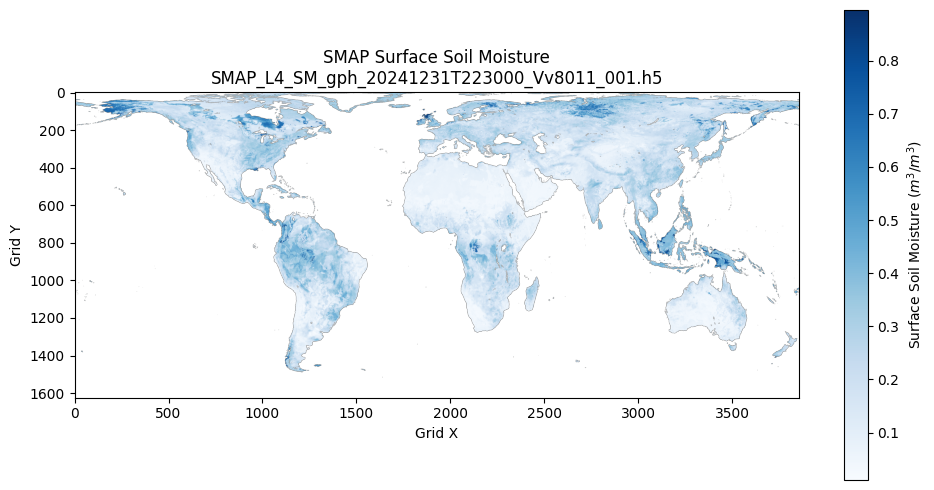

In [21]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

file_path = str(files[0])

with h5py.File(file_path, "r") as h5_file:
    # 1. Read surface soil moisture
    # Fill value for missing/masked pixels is typically -9999.0
    sm_ds = h5_file["Geophysical_Data/sm_surface"]
    sm_data = sm_ds[:]
    fill_value = sm_ds.attrs.get("_FillValue", -9999.0)

    # 2. Mask invalid / no-data values
    sm_data = np.where(sm_data == fill_value, np.nan, sm_data)

# 3. Quick plot
plt.figure(figsize=(10, 5))
plt.imshow(sm_data, cmap="Blues", origin="upper")
plt.colorbar(label="Surface Soil Moisture ($m^3/m^3$)")
plt.title(f"SMAP Surface Soil Moisture\n{files[0].name}")
plt.xlabel("Grid X")
plt.ylabel("Grid Y")
plt.tight_layout()
plt.show()

In [28]:
import h5py

with h5py.File(str(files[0]), "r") as h5:
    dataset = h5["Geophysical_Data/sm_surface"]
    print("Shape:     ", dataset.shape)
    print("Data Type: ", dataset.dtype)
    print("Attributes:")
    for attr_name, attr_val in dataset.attrs.items():
        print(f"  - {attr_name}: {attr_val}")

Shape:      (1624, 3856)
Data Type:  float32
Attributes:
  - DIMENSION_LABELS: [b'y' b'x']
  - DIMENSION_LIST: [array([<HDF5 object reference>], dtype=object)
 array([<HDF5 object reference>], dtype=object)]
  - _FillValue: -9999.0
  - coordinates: b'/cell_lat /cell_lon'
  - fmissing_value: -9999.0
  - grid_mapping: b'EASE2_global_projection'
  - long_name: b'Top layer soil moisture (0-5 cm)'
  - missing_value: -9999.0
  - units: b'm3 m-3'
  - valid_max: 0.8999999761581421
  - valid_min: 0.0


* Get all the sm data

In [25]:
import h5py
import numpy as np

time_series_data = []

for f in files:
    with h5py.File(str(f), "r") as h5:
        data = h5["Geophysical_Data/sm_surface"][:]
        data = np.where(data == -9999.0, np.nan, data)
        time_series_data.append(data)

# Stack into 3D array: (time, lat, lon)
sm_stack = np.array(time_series_data)
print("Time series stack shape:", sm_stack.shape)

Time series stack shape: (10, 1624, 3856)


### Step 1: Find the Grid Coordinates (Latitude / Longitude)

SMAP L4 files use an EASE-Grid 2.0. You can extract the pixel coordinates corresponding to your target farm or bounding box:

python

In [29]:
import h5py
import numpy as np
import pandas as pd
import datetime

# Target location (e.g. your farm or study site latitude/longitude)
TARGET_LAT = 34.05  # Change to your target latitude
TARGET_LON = -111.5 # Change to your target longitude

# Read lat/lon grid coordinates from the first file
with h5py.File(str(files[0]), "r") as h5:
    # Most L4 SMAP products provide lat/lon arrays or 1D coordinates
    # For SPL4SMGP, lat/lon 2D or 1D arrays are stored in Geophysical_Data or Cell_Data:
    if "cell_lat" in h5.get("Geophysical_Data", {}):
        lats = h5["Geophysical_Data/cell_lat"][:]
        lons = h5["Geophysical_Data/cell_lon"][:]
    elif "latitude" in h5.get("cell_data", {}):
        lats = h5["cell_data/latitude"][:]
        lons = h5["cell_data/longitude"][:]
    else:
        # Standard SPL4SMGP EASE-Grid dimensions
        lats = None
        lons = None

# If coordinates are 2D arrays, find nearest row and col index:
if lats is not None:
    dist = (lats - TARGET_LAT)**2 + (lons - TARGET_LON)**2
    row_idx, col_idx = np.unravel_index(np.argmin(dist), dist.shape)
    print(f"Nearest pixel found at row: {row_idx}, col: {col_idx}")
else:
    # If using spatial subset or mean across the whole extracted region:
    row_idx, col_idx = slice(None), slice(None)

In [30]:
import re

records = []

for f in sorted(files):
    filename = f.name if hasattr(f, "name") else str(f)
    
    # 1. Parse timestamp from filename (e.g., 20250101T013000)
    match = re.search(r"(\d{8}T\d{6})", filename)
    timestamp = datetime.datetime.strptime(match.group(1), "%Y%m%dT%H%M%S") if match else None

    with h5py.File(str(f), "r") as h5:
        # Extract surface and root zone soil moisture
        sm_s = h5["Geophysical_Data/sm_surface"][:]
        sm_rz = h5["Geophysical_Data/sm_rootzone"][:]
        surf_temp = h5["Geophysical_Data/surface_temp"][:] if "surface_temp" in h5["Geophysical_Data"] else None

        # Mask fill values (-9999.0)
        sm_s = np.where(sm_s == -9999.0, np.nan, sm_s)
        sm_rz = np.where(sm_rz == -9999.0, np.nan, sm_rz)
        if surf_temp is not None:
            surf_temp = np.where(surf_temp == -9999.0, np.nan, surf_temp)

        # Extract for target pixel or spatial mean
        if isinstance(row_idx, int):
            s_val = sm_s[row_idx, col_idx]
            rz_val = sm_rz[row_idx, col_idx]
            temp_val = surf_temp[row_idx, col_idx] if surf_temp is not None else np.nan
        else:
            s_val = np.nanmean(sm_s)
            rz_val = np.nanmean(sm_rz)
            temp_val = np.nanmean(surf_temp) if surf_temp is not None else np.nan

        records.append({
            "datetime": timestamp,
            "sm_surface": float(s_val),
            "sm_rootzone": float(rz_val),
            "surface_temp_k": float(temp_val)
        })

# Create a clean time-series DataFrame
df = pd.DataFrame(records).sort_values("datetime").reset_index(drop=True)
df.set_index("datetime", inplace=True)
df

,sm_surface,sm_rootzone,surface_temp_k
datetime,,,
2024-12-31 22:30:00,0.202864,0.234299,278.866364
2025-01-01 01:30:00,0.203312,0.234390,278.689819
2025-01-01 04:30:00,0.203193,0.234434,279.716919
2025-01-01 07:30:00,0.203359,0.234472,281.246887
2025-01-01 10:30:00,0.203006,0.234467,282.059265
2025-01-01 13:30:00,0.202576,0.234420,281.805603
2025-01-01 16:30:00,0.202580,0.234382,280.539459
2025-01-01 19:30:00,0.202860,0.234404,279.347412
2025-01-01 22:30:00,0.203179,0.234462,278.293518


In [31]:
# 1. Profile Moisture Differential & Ratio
# Indicates whether topsoil is drying out faster than roots can drink, or if rain is percolating down
df["moisture_gradient"] = df["sm_surface"] - df["sm_rootzone"]
df["profile_ratio"] = df["sm_surface"] / (df["sm_rootzone"] + 1e-6)

# 2. Moisture Depletion / Infiltration Rates (1st Derivative)
# Negative values = drydown / evapotranspiration; Positive values = recharge / precipitation
df["surface_delta_3h"] = df["sm_surface"].diff()
df["rootzone_delta_3h"] = df["sm_rootzone"].diff()

# 3. Rolling Agronomic Dynamics (e.g. 24h & 7-day windows when you have longer series)
# Rolling means smooth out 3-hourly diurnal fluctuations
df["sm_surface_rolling_mean_24h"] = df["sm_surface"].rolling("24h", min_periods=1).mean()
df["sm_rootzone_rolling_mean_24h"] = df["sm_rootzone"].rolling("24h", min_periods=1).mean()

# 4. Drydown Rate (Evapotranspiration proxy)
# How rapidly the soil lost moisture over the last 24 hours
df["surface_drydown_24h"] = df["sm_surface"] - df["sm_surface"].shift(8) # 8 steps * 3 hours = 24h

# 5. Crop Water Stress Index proxy (CWSI / Relative Soil Water Content)
# Normalizes moisture between field permanent wilting point (PWP) and field capacity (FC)
theta_min = df["sm_rootzone"].min()
theta_max = df["sm_rootzone"].max()
if theta_max > theta_min:
    df["relative_extractable_water"] = (df["sm_rootzone"] - theta_min) / (theta_max - theta_min)

### Why these features matter for ML models:
* **relative_extractable_water**: Direct indicator of drought stress affecting crop yield. 
* **moisture_gradient**: Highlights whether water is moving downward (recharging roots) or upward (surface drying / high evaporative demand). 

* **surface_delta & surface_drydown**: Strong proxy for actual evapotranspiration ($ET$) and infiltration without needing weather stations on site.

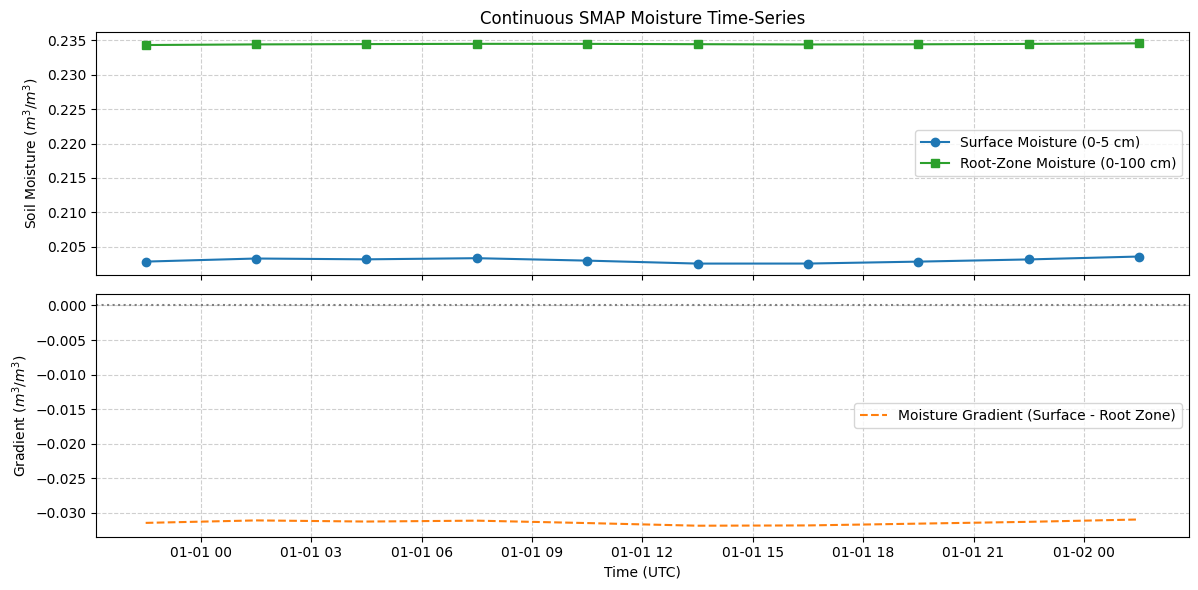

In [32]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

# Plot Raw Time Series
ax1.plot(df.index, df["sm_surface"], label="Surface Moisture (0-5 cm)", marker="o", color="#1f77b4")
ax1.plot(df.index, df["sm_rootzone"], label="Root-Zone Moisture (0-100 cm)", marker="s", color="#2ca02c")
ax1.set_ylabel("Soil Moisture ($m^3/m^3$)")
ax1.grid(True, linestyle="--", alpha=0.6)
ax1.legend()
ax1.set_title("Continuous SMAP Moisture Time-Series")

# Plot Agronomic Gradient / Delta
ax2.plot(df.index, df["moisture_gradient"], label="Moisture Gradient (Surface - Root Zone)", color="#ff7f0e", linestyle="--")
ax2.axhline(0, color="gray", linestyle=":")
ax2.set_ylabel("Gradient ($m^3/m^3$)")
ax2.set_xlabel("Time (UTC)")
ax2.grid(True, linestyle="--", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

### Balancing the Dataset

Agricultural data is often skewed, which can lead to inaccurate predictive results. Apply the Synthetic Minority Oversampling Technique (SMOTE) to balance your engineered dataset. Utilizing SMOTE shifts the decision thresholds and significantly improves the precision, recall, and overall performance of machine learning classifiers.   

### Feature Engineering

Combine the extracted SMAP data with local meteorological variables to calculate the Water Balance Ratio (WBR), defined as the ratio of precipitation to reference evapotranspiration. This metric directly quantifies the intensity of water stress or abundance at a specific location.   